## Investigacion y comparacion entre solvers milp

Esta notebook nace de que necesito poder verificar si aco funciona adecuadamente, y para verificar su correctitud quiero utilizar milkp. Pero como es bien sabido que milp necesita mas tiempo de computo no estoy encontrando el tiempo adecuado que hay que dejar que compute para que encuentre la solucuion. Por ende nace esta notebook para comprender un poco como crece el tiempo de computo segun crece la instancia del problema y las diferencias entre los solvers.

A continuacion se va a correr las siguientes instancias:

- Instancia chica

```bash
taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=10 \
  experiments.num_vehicles=5,10,15 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'

taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=20 \
  experiments.num_vehicles=5,10,15 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'
```

- Instancia mediana

```bash
taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=30 \
  experiments.num_vehicles=20,30,50 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'

taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=45 \
  experiments.num_vehicles=20,30,40 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'
```

- Instancia grande

```bash
taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=65 \
  experiments.num_vehicles=35,45,50 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'

taskset -c 3,4,5,6 python3 main.py -m \
  hydra/launcher=joblib \
  hydra.launcher.n_jobs=4 \
  experiments.num_customers=80 \
  experiments.num_vehicles=40,60,70 \
  experiments.timeout=7200  \
  solvers.milp.solver=highs,gurobi,cbc,glpk \
  'experiments.name=milp_understanding_C${experiments.num_customers}_V${experiments.num_vehicles}_${solvers.milp.solver}'
```


In [1]:
import psycopg2
import pandas as pd
import re 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

conn = psycopg2.connect(
    dbname="results",
    user="tmarmay",
    password="tmarmay",
    host="localhost",
    port=5432
)

query = "SELECT * FROM run_results;"
df = pd.read_sql(query, conn)
conn.close()

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_C(text):
        match = re.search(r'C(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_V(text):
        match = re.search(r'V(\d+)', text)
        return float(match.group(1)) if match else None

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["c"] = df["experiment_id"].apply(extract_C)
    df["v"] = df["experiment_id"].apply(extract_V)
    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = (2*c*v*n) + (3*(n**2)*v) + (2*v*c) + v
    return df


df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="milpaco_"))
df = df[df['feasible'] == True]
df = df[df['solver'] != 'ACO']

/tmp/ipykernel_4410/4020456043.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


### Tiempos de computo

Comparacion de tiempos entre los solvers para encontrar solucion a distintos tamanos del problema. 
- Fija un c y varia para 3 v
- Repeti para tres c distintos
Intenta sacar alguna aproximacion

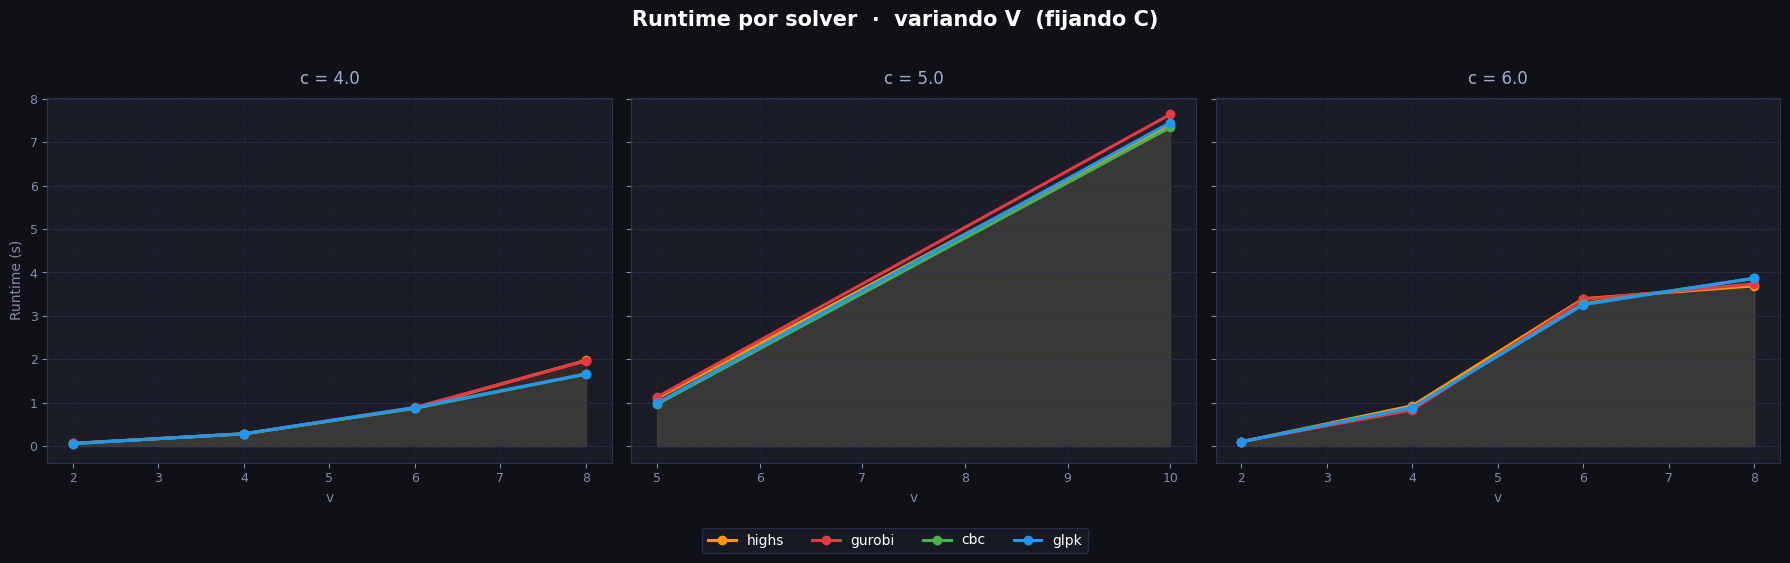

In [2]:
SOLVER_COLORS = {
    "gurobi": "#E63946",   # rojo
    "glpk": "#2196F3",   # azul
    "cbc": "#4CAF50",   # verde
    "highs": "#FF9800",   # naranja
}

def plot_runtime_by_v(df: pd.DataFrame, solver_colors: dict = SOLVER_COLORS):
    # Valores únicos de c (tomamos los 3 primeros o los que haya)
    c_values = sorted(df["c"].unique())[:3]
    solvers  = df["solver"].unique()

    fig, axes = plt.subplots(
        1, len(c_values),
        figsize=(6 * len(c_values), 5),
        sharey=True,
    )
    if len(c_values) == 1:
        axes = [axes]

    fig.patch.set_facecolor("#0F1117")
    fig.suptitle(
        "Runtime por solver  ·  variando V  (fijando C)",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for ax, c_val in zip(axes, c_values):
        ax.set_facecolor("#1A1D27")
        ax.set_title(f"c = {c_val}", color="#AAAACC", fontsize=12, pad=10)

        subset = df[df["c"] == c_val]

        for solver in solvers:
            color = solver_colors.get(solver, "#CCCCCC")
            s = (
                subset[subset["solver"] == solver]
                .groupby("v")["runtime"]
                .mean()
                .reset_index()
                .sort_values("v")
            )
            if s.empty:
                continue
            ax.plot(
                s["v"], s["runtime"],
                marker="o", linewidth=2.2, markersize=6,
                color=color, label=solver,
            )
            ax.fill_between(s["v"], s["runtime"], alpha=0.08, color=color)

        # Estilo ejes
        for spine in ax.spines.values():
            spine.set_edgecolor("#2E3250")
        ax.tick_params(colors="#8888AA", labelsize=9)
        ax.set_xlabel("v", color="#8888AA", fontsize=10)
        ax.xaxis.set_major_locator(ticker.AutoLocator())
        ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
        ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    axes[0].set_ylabel("Runtime (s)", color="#8888AA", fontsize=10)

    # Leyenda global
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=len(solvers),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()

plot_runtime_by_v(df)

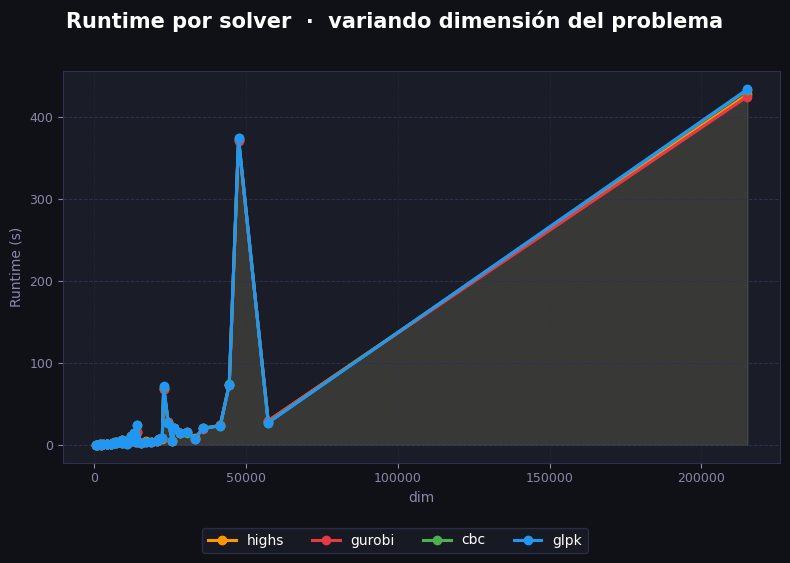

In [3]:
def plot_runtime_by_dim(df: pd.DataFrame, solver_colors: dict = SOLVER_COLORS):
    solvers = df["solver"].unique()

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#0F1117")
    ax.set_facecolor("#1A1D27")
    fig.suptitle(
        "Runtime por solver  ·  variando dimensión del problema",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for solver in solvers:
        color = solver_colors.get(solver, "#CCCCCC")
        s = (
            df[df["solver"] == solver]
            .groupby("dim")["runtime"]
            .mean()
            .reset_index()
            .sort_values("dim")
        )
        if s.empty:
            continue
        ax.plot(
            s["dim"], s["runtime"],
            marker="o", linewidth=2.2, markersize=6,
            color=color, label=solver,
        )
        ax.fill_between(s["dim"], s["runtime"], alpha=0.08, color=color)

    for spine in ax.spines.values():
        spine.set_edgecolor("#2E3250")
    ax.tick_params(colors="#8888AA", labelsize=9)
    ax.set_xlabel("dim", color="#8888AA", fontsize=10)
    ax.set_ylabel("Runtime (s)", color="#8888AA", fontsize=10)
    ax.xaxis.set_major_locator(ticker.AutoLocator())
    ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
    ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=len(solvers),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()

plot_runtime_by_dim(df)

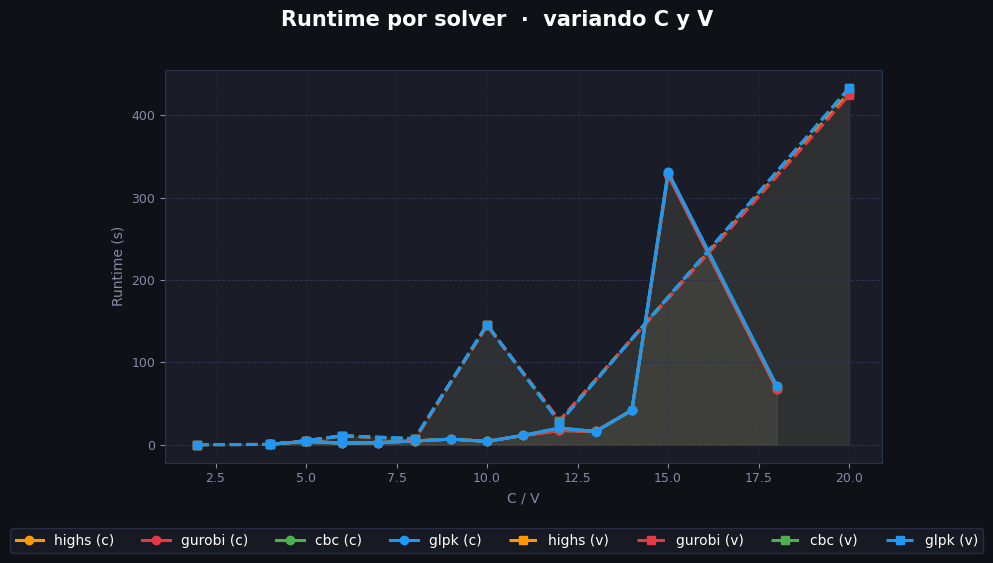

In [4]:
def plot_runtime_by_c_and_v(df: pd.DataFrame, solver_colors: dict = SOLVER_COLORS):
    solvers = df["solver"].unique()

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#0F1117")
    ax.set_facecolor("#1A1D27")
    fig.suptitle(
        "Runtime por solver  ·  variando C y V",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    handles_labels = {}

    for col, linestyle, marker in [("c", "-", "o"), ("v", "--", "s")]:
        for solver in solvers:
            color = solver_colors.get(solver, "#CCCCCC")
            s = (
                df[df["solver"] == solver]
                .groupby(col)["runtime"]
                .mean()
                .reset_index()
                .sort_values(col)
            )
            if s.empty:
                continue
            label = f"{solver} ({col})"
            line, = ax.plot(
                s[col], s["runtime"],
                marker=marker, linewidth=2.2, markersize=6,
                color=color, linestyle=linestyle, label=label,
            )
            ax.fill_between(s[col], s["runtime"], alpha=0.05, color=color)
            handles_labels[label] = line

    for spine in ax.spines.values():
        spine.set_edgecolor("#2E3250")
    ax.tick_params(colors="#8888AA", labelsize=9)
    ax.set_xlabel("C / V", color="#8888AA", fontsize=10)
    ax.set_ylabel("Runtime (s)", color="#8888AA", fontsize=10)
    ax.xaxis.set_major_locator(ticker.AutoLocator())
    ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
    ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    fig.legend(
        handles_labels.values(), handles_labels.keys(),
        loc="lower center", ncol=len(handles_labels),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()
    
plot_runtime_by_c_and_v(df)

### Comparacion soluciones 

Grafico de comparacion de precios entre los solvers para isntancias feasibles, osea comparar cual solver da mejores soluciones

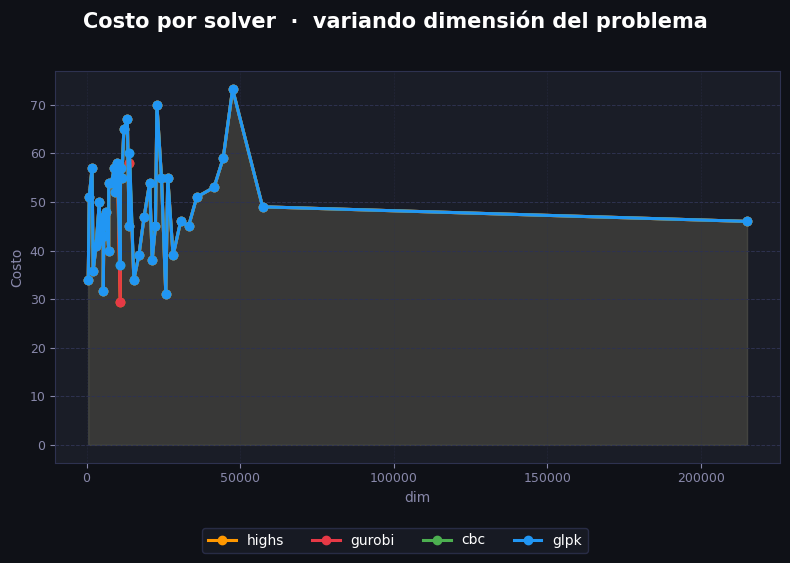

In [28]:
def plot_cost_by_dim(df: pd.DataFrame, solver_colors: dict = SOLVER_COLORS):
    solvers = df["solver"].unique()

    fig, ax = plt.subplots(figsize=(8, 5))
    fig.patch.set_facecolor("#0F1117")
    ax.set_facecolor("#1A1D27")
    fig.suptitle(
        "Costo por solver  ·  variando dimensión del problema",
        color="white", fontsize=15, fontweight="bold", y=1.02,
    )

    for solver in solvers:
        color = solver_colors.get(solver, "#CCCCCC")
        s = (
            df[df["solver"] == solver]
            .groupby("dim")["cost"]
            .mean()
            .reset_index()
            .sort_values("dim")
        )
        if s.empty:
            continue
        ax.plot(
            s["dim"], s["cost"],
            marker="o", linewidth=2.2, markersize=6,
            color=color, label=solver,
        )
        ax.fill_between(s["dim"], s["cost"], alpha=0.08, color=color)

    for spine in ax.spines.values():
        spine.set_edgecolor("#2E3250")
    ax.tick_params(colors="#8888AA", labelsize=9)
    ax.set_xlabel("dim", color="#8888AA", fontsize=10)
    ax.set_ylabel("Costo", color="#8888AA", fontsize=10)
    ax.xaxis.set_major_locator(ticker.AutoLocator())
    ax.grid(axis="y", color="#2E3250", linewidth=0.7, linestyle="--")
    ax.grid(axis="x", color="#2E3250", linewidth=0.4, linestyle=":")

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center", ncol=len(solvers),
        facecolor="#1A1D27", edgecolor="#2E3250",
        labelcolor="white", fontsize=10,
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout()
    plt.show()
plot_cost_by_dim(df[df['cost'] > 0])

Veamos si podemos encontrar alguna relacion con el tamano del problema y el runtime que deberiamos dar para que los solvers milp lleguen a la solucion.

### Ley de potencia

Primero proponemos que el runtime tiene cun comportamiento exponencial respescto al c y v, por lo tanto realizamos lo siguente:

$runtime = a * c ^ \alpha * v ^ \beta$ 
- a: constante
- c: customers
- v : vehicles
- $ \alpha $ : factor de crecimiento c
- $ \beta $ : factor de crecimiento v

Luego aplicamos log para bajar el exponente y nos queda una ecuacion de una recta. 

$$ ln(runtime) = ln(a) + \alpha * ln(c) + \beta * ln(v) $$

Y hacemos una regrecion lineal multiple para estimar alfa y beta (no porque creemos que la relacion es lineal, sino porque llevamos el problema de exponencial a lineal). 

Luego lo que hacemos es graficar los puntos $$ln(runtime real) vs log(runtime predicho)$$ y si es parecido a una recta identidad es porque estan relacionados

Conclucion: Hay una buena relacion, podriamos usar esta ecuacion para predecir el runtime de cada ejemplo. Para mas fiabilidad, como podemos ver en el grafico a continuacion, realizamos $y = x + k$ lo que nos ayuda para los casos en los que predecimos un tiempo menor al tiempo real.

In [22]:
# Porque estoy buscando la mejor configuración que logra factibilidad
df_f = df[(df['feasible'] == True) & (df['status'] != 'timeout') & (df['runtime'] > 0.0)]

# Deberia quedarme con el minimo runtime para un c y v fijo ? 
#df_f = df_f.loc[df_f.groupby(['c', 'v'])['runtime'].idxmax()]


Model: ants = a * c^alpha * v^beta
a      = 0.0002
alpha  = 2.5868  (influence of customers)
beta  = 2.4120  (influence of vehicles)
R^2    = 0.8995


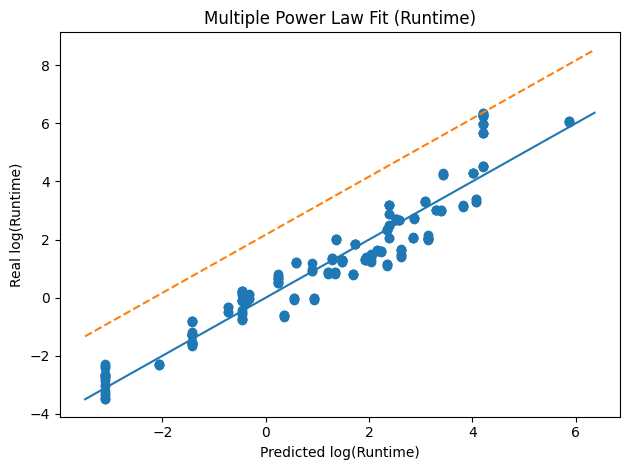


Modelo estimado:
runtime = 0.000234 * c^2.586751 * v^2.411992

Modelo seguro (cota superior):
runtime_safe = 0.002036 * c^2.586751 * v^2.411992
(equivalente a multiplicar por 8.721093)


In [26]:
from sklearn.linear_model import LinearRegression

def fit_multiple_power_law(best_df):

    # Variables independientes (log transformadas)
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Variable dependiente
    y = np.log(best_df["runtime"].values)

    model = LinearRegression()
    model.fit(X, y)

    alpha = model.coef_[0]   # exponente para c
    beta = model.coef_[1]   # exponente para v
    log_a = model.intercept_
    a = np.exp(log_a)

    r2 = model.score(X, y)

    print("Model: ants = a * c^alpha * v^beta")
    print(f"a      = {a:.4f}")
    print(f"alpha  = {alpha:.4f}  (influence of customers)")
    print(f"beta  = {beta:.4f}  (influence of vehicles)")
    print(f"R^2    = {r2:.4f}")

    return model


def plot_multiple_fit(best_df, model):

    # Construimos X nuevamente
    X = np.column_stack([
        np.log(best_df["c"].values),
        np.log(best_df["v"].values)
    ])

    # Valores reales
    y_real = np.log(best_df["runtime"].values)

    # Valores predichos
    y_pred = model.predict(X)

    plt.figure()
    plt.scatter(y_pred, y_real)

    # Línea ideal y = x
    min_val = min(y_pred.min(), y_real.min())
    max_val = max(y_pred.max(), y_real.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    # Linea segura y = x + k
    residuals = y_real - y_pred
    k = residuals.max()
    plt.plot([min_val, max_val],
             [min_val + k, max_val + k],
             linestyle="--",
             label=f"y = x + {k:.3f}")

    plt.xlabel("Predicted log(Runtime)")
    plt.ylabel("Real log(Runtime)")
    plt.title("Multiple Power Law Fit (Runtime)")
    plt.tight_layout()
    plt.show()
    return k

model = fit_multiple_power_law(df_f)
k = plot_multiple_fit(df_f, model)


alpha = model.coef_[0]   # exponente para c
beta = model.coef_[1]   # exponente para v
log_a = model.intercept_
a = np.exp(log_a)
safe_multiplier = np.exp(k)

print("\nModelo estimado:")
print(f"runtime = {a:.6f} * c^{alpha:.6f} * v^{beta:.6f}")

print("\nModelo seguro (cota superior):")
print(f"runtime_safe = {a * safe_multiplier:.6f} * c^{alpha:.6f} * v^{beta:.6f}")
print(f"(equivalente a multiplicar por {safe_multiplier:.6f})")
